In [87]:
import numpy as np
from pprint import pprint
from scipy.signal import find_peaks, argrelextrema, peak_widths
from matplotlib import pyplot as plt
from sklearn.mixture import GaussianMixture

In [3]:
x = np.linspace(-1, 1, 100)
BIN_WIDTH = 0.02
c_vals = [3, 4, 5, 5.2, 5.3, 5.33, 5.5, 5.6, 6, 7]
n_realizations = 100000

In [4]:
def get_densities(run_name, n_realizations, n_last_rows=20):
    data_filename = f"runs/{run_name}/data/cnts_{run_name}.txt"

    with open(data_filename, "rb") as f:
        lines = f.readlines()

    last_counts_rows = [
        np.fromstring(line, sep=" ", dtype=np.float64) for line in lines
    ][-3 * n_last_rows :]

    # normalize and drop first element (timestep index)
    last_densities = [
        counts[1:] / (n_realizations * BIN_WIDTH) for counts in last_counts_rows
    ]
    return last_densities

In [5]:
all_ps = []
for c_val in c_vals:
    run_name = (f"pow_sym_ref_init-dem_q2_c{c_val}_dt1e-05_nr100000_rs0_bins100_cnts-step1000")
    densities = get_densities(run_name, n_realizations)
    all_ps.append(densities)


In [6]:
all_a_ps = []
all_b_ps = []
all_c_ps = []
for p in all_ps:
    a_ps = p[0::3]
    b_ps = p[1::3]
    c_ps = p[2::3]
    all_a_ps.append(a_ps)
    all_b_ps.append(b_ps)
    all_c_ps.append(c_ps)

In [7]:
selected_inds = [2,7,-1]
aps_selected = [all_a_ps[i] for i in selected_inds]
bps_selected = [all_b_ps[i] for i in selected_inds]
cps_selected = [all_c_ps[i] for i in selected_inds]
cs_selected = [c_vals[i] for i in selected_inds]
print(cs_selected)

[5, 5.6, 7]


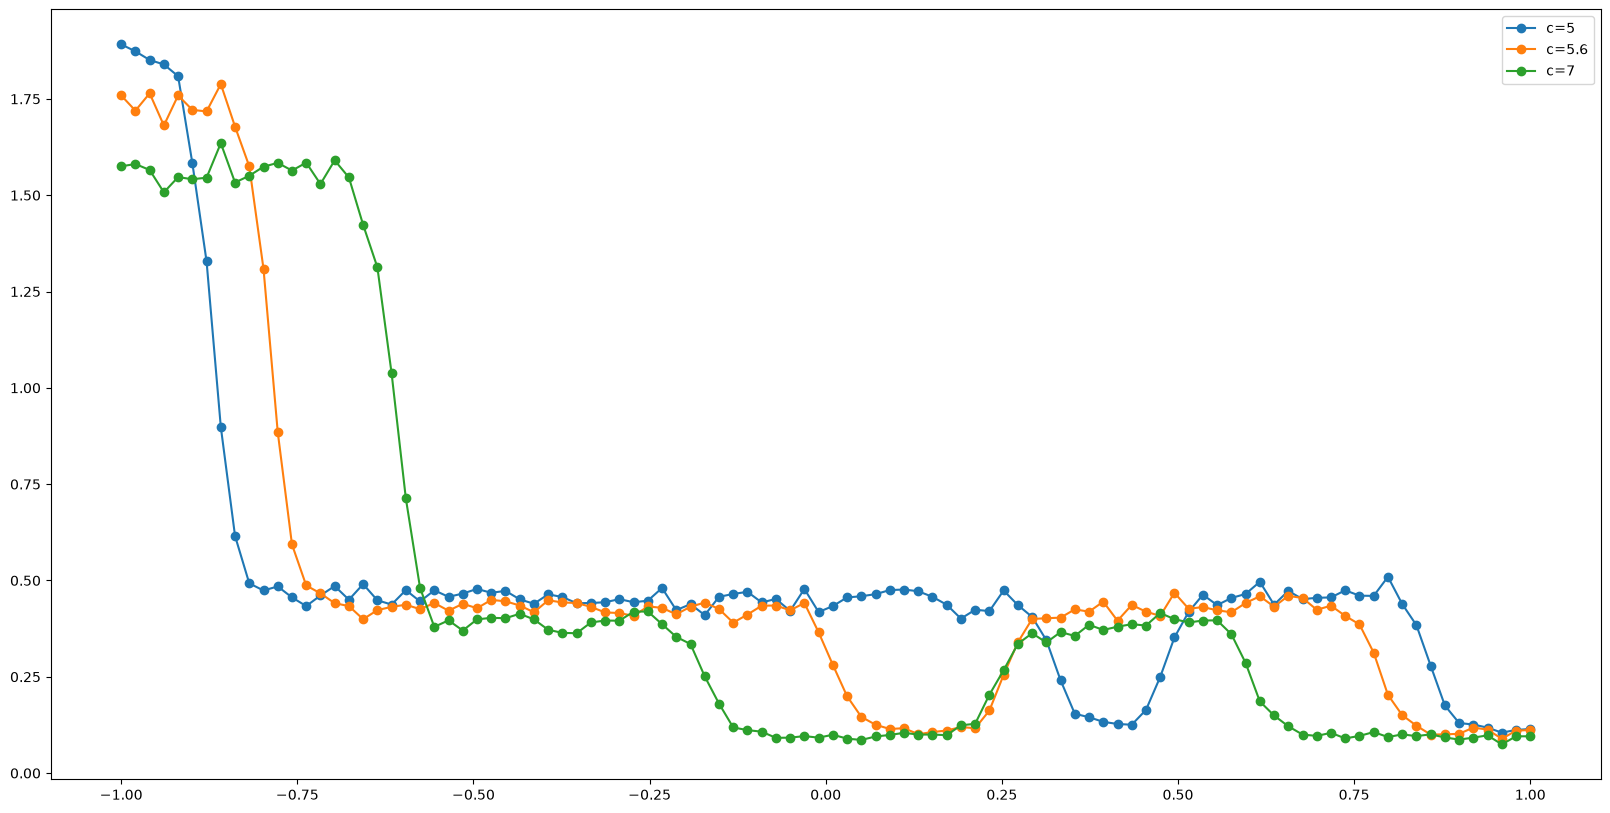

In [8]:
fig, ax = plt.subplots(figsize=(20,10))
for pas, c in zip(aps_selected, cs_selected):
    pa = pas[-1]
    ax.plot(x, pa, "-o", label=f"c={c}")
plt.legend()
plt.show()

main_peak: 70
widths: [0.14790511]
main_peak: 59
widths: [0.23319889]
main_peak: 47
widths: [0.39701201]


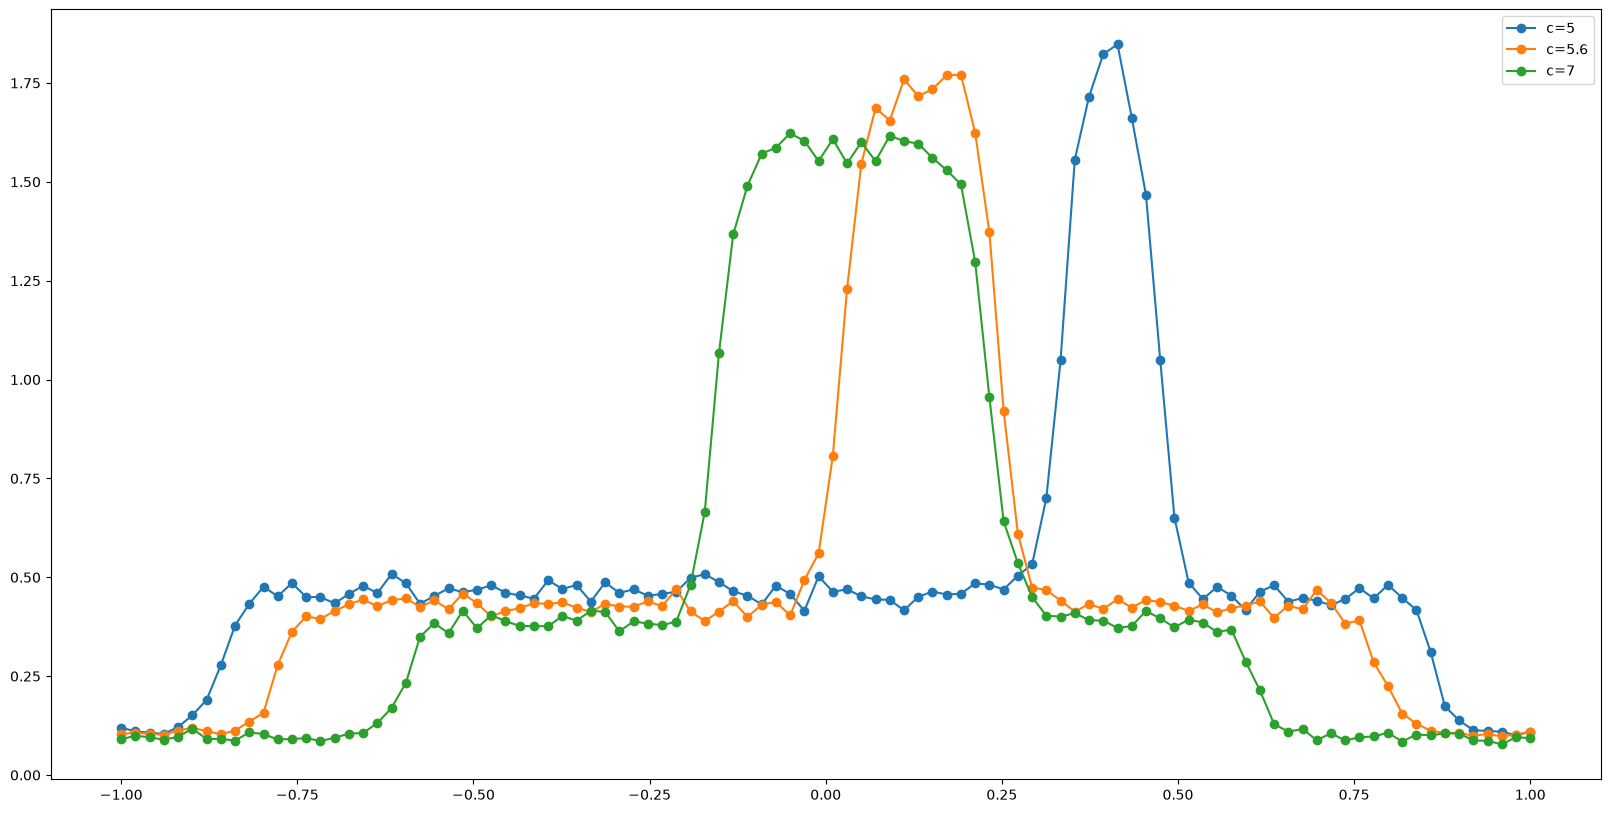

In [68]:
fig, ax = plt.subplots(figsize=(20,10))
for pbs, c in zip(bps_selected, cs_selected):
    pb = pbs[-1]
    main_peak = np.argmax(pb)
    print(f"main_peak: {main_peak}")
    widths = peak_widths(pb, [main_peak])
    print(f"widths: {widths[0] * 0.02}")
    ax.plot(x, pb, "-o", label=f"c={c}")
plt.legend()
plt.show()

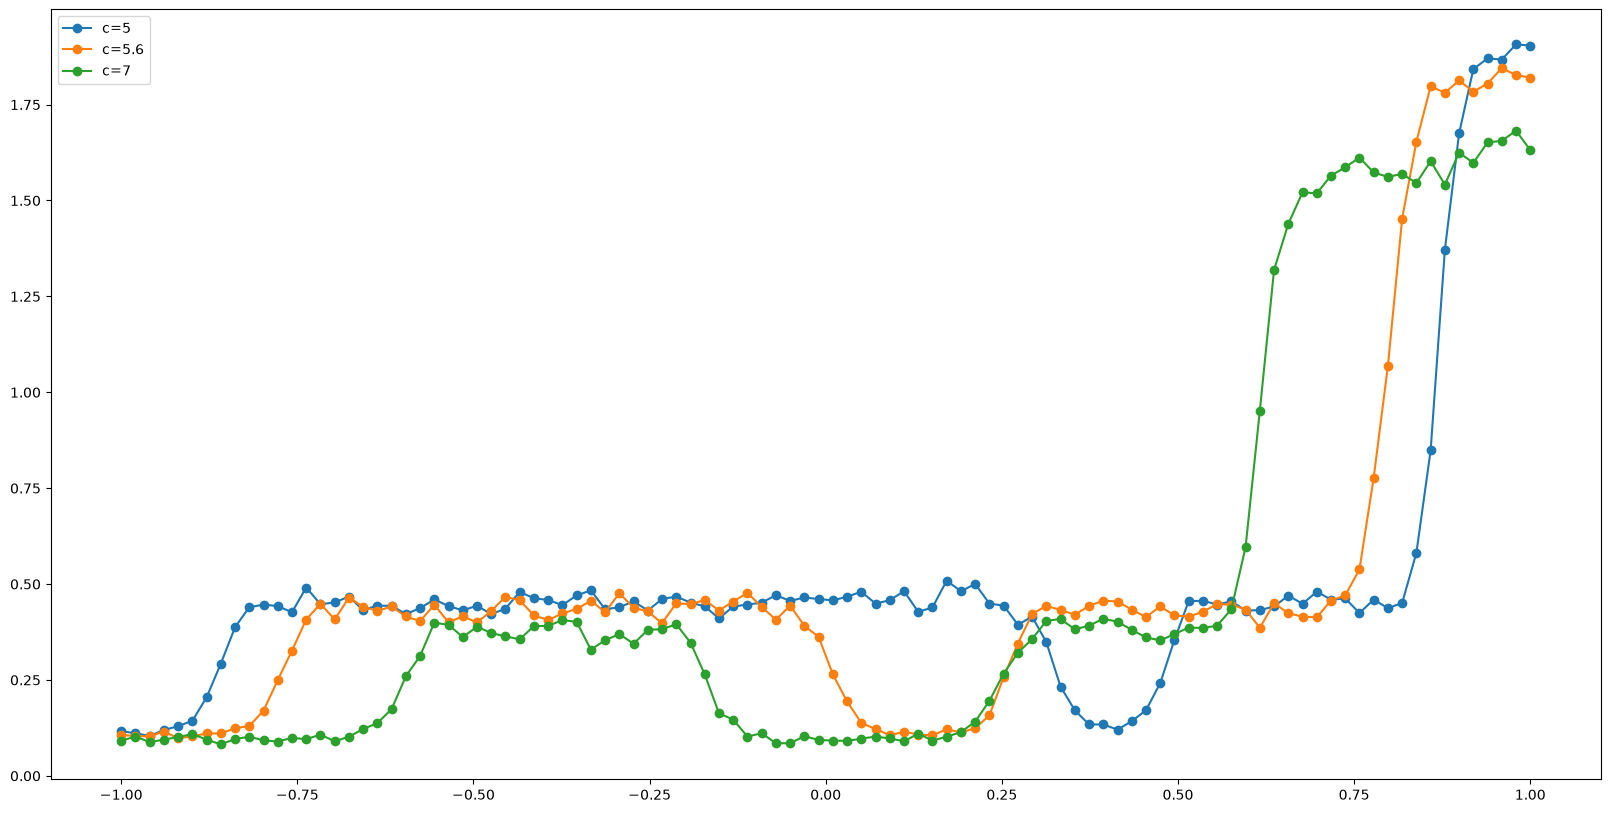

In [10]:
fig, ax = plt.subplots(figsize=(20,10))
for pcs, c in zip(cps_selected, cs_selected):
    pc = pcs[-1]
    ax.plot(x, pc, "-o", label=f"c={c}")
plt.legend()
plt.show()

In [83]:
def peak_width(x, y, background, *, bounds=None):
    """
    Half-height width of the region containing the global maximum.

    Interior edges: linearly interpolated threshold crossings.
    Boundary edges: clipped to the domain boundary.

    bounds: optional (xmin, xmax), e.g. (-1, 1), useful if x contains
            bin centers rather than the actual domain endpoints.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.shape != x.shape or x.size < 2:
        raise ValueError("x and y must be matching 1D arrays.")
    if not (np.all(np.isfinite(x)) and np.all(np.isfinite(y))):
        raise ValueError("Data must be finite.")
    if np.any(np.diff(x) <= 0):
        raise ValueError("x must be strictly increasing.")
    if not np.isfinite(background) or y.max() <= background:
        raise ValueError("Background must be finite and below the maximum.")

    xmin, xmax = (x[0], x[-1]) if bounds is None else bounds
    if not (np.isfinite(xmin) and np.isfinite(xmax)
            and xmin <= x[0] and xmax >= x[-1]):
        raise ValueError("Bounds must enclose the sampled x values.")

    p = np.argmax(y)
    level = background + 0.5 * (y[p] - background)

    # Walk outward from the maximum while above the threshold.
    left = p
    while left > 0 and y[left - 1] >= level:
        left -= 1

    right = p
    while right < len(y) - 1 and y[right + 1] >= level:
        right += 1

    def crossing(i, j):
        return (
            x[i]
            + (level - y[i]) * (x[j] - x[i]) / (y[j] - y[i])
        )

    xl = xmin if left == 0 else crossing(left - 1, left)
    xr = xmax if right == len(y) - 1 else crossing(right, right + 1)

    return {
        "width": xr - xl,
        "left": xl,
        "right": xr,
        "level": level,
        "touches_left": left == 0,
        "touches_right": right == len(y) - 1,
    }

In [114]:
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

def histogram_background(
    y, *, bins=60, smooth=1.0, prominence=0.12, min_height=0.15
):
    """
    Estimate the intermediate plateau for profiles with:
        low floor < intermediate plateau << high peak.

    prominence and min_height are relative to the largest smoothed
    histogram count. They filter weak, isolated histogram bumps.

    Returns:
        background, selected_mask, diagnostics
    """
    y = np.asarray(y, dtype=float)

    if y.ndim != 1 or y.size < 5:
        raise ValueError("Expected a 1D array with at least 5 samples.")
    if not np.all(np.isfinite(y)) or np.ptp(y) == 0:
        raise ValueError("Data must be finite and nonconstant.")
    if smooth <= 0:
        raise ValueError("smooth must be positive.")

    # Separate the high-density population from the lower plateaus.
    cutoff = y.min() + 0.5 * np.ptp(y)
    lower = y[y < cutoff]

    counts, edges = np.histogram(
        lower, bins=bins, range=(y.min(), cutoff)
    )
    centers = 0.5 * (edges[:-1] + edges[1:])
    filtered = gaussian_filter1d(counts.astype(float), sigma=smooth)

    # Padding allows detection of a mode at either histogram endpoint.
    padded = np.r_[0.0, filtered, 0.0]
    peaks, _ = find_peaks(
        padded,
        prominence=prominence * filtered.max(),
        height=min_height * filtered.max(),
    )
    peaks = peaks - 1
    peaks = peaks[(peaks >= 0) & (peaks < len(counts))]

    if peaks.size == 0:
        raise ValueError("No significant background histogram mode found.")

    # Highest DENSITY mode, not tallest histogram peak.
    chosen = peaks[-1]

    # Refine using original samples in bins around the selected mode.
    radius = max(1, int(np.ceil(smooth)))
    lo = max(0, chosen - radius)
    hi = min(len(counts) - 1, chosen + radius)

    mask = (y >= edges[lo]) & (y < edges[hi + 1])
    background = np.median(y[mask])

    diagnostics = {
        "counts": counts,
        "edges": edges,
        "centers": centers,
        "smoothed": filtered,
        "modes": centers[peaks],
        "cutoff": cutoff,
    }
    return background, mask, diagnostics

Candidate lower-density modes: [0.11244375 0.45485625]
Selected background: 0.456
Peak width: 0.12846744511470942


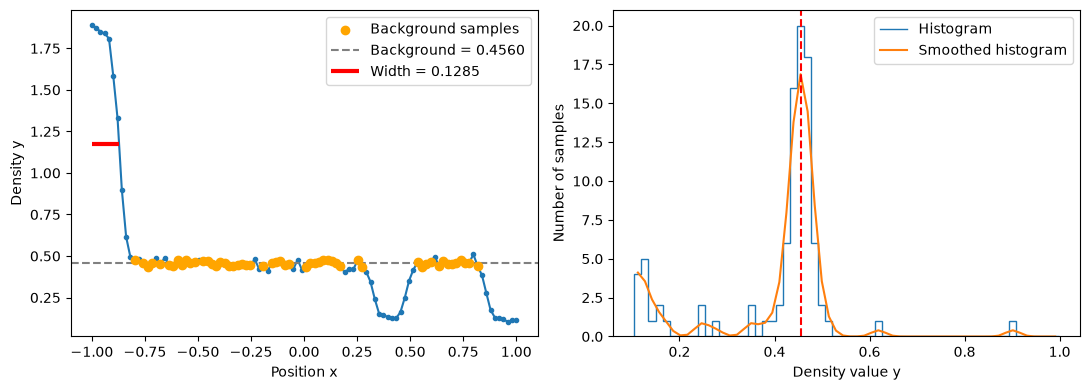

Candidate lower-density modes: [0.09608125 0.43598125]
Selected background: 0.432
Peak width: 0.211489898989899


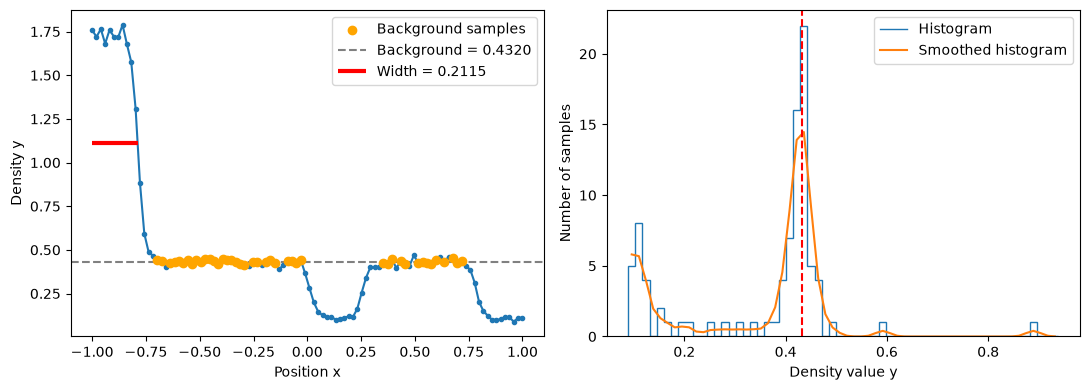

Candidate lower-density modes: [0.09400625 0.38009792]
Selected background: 0.3865
Peak width: 0.38550372756844253


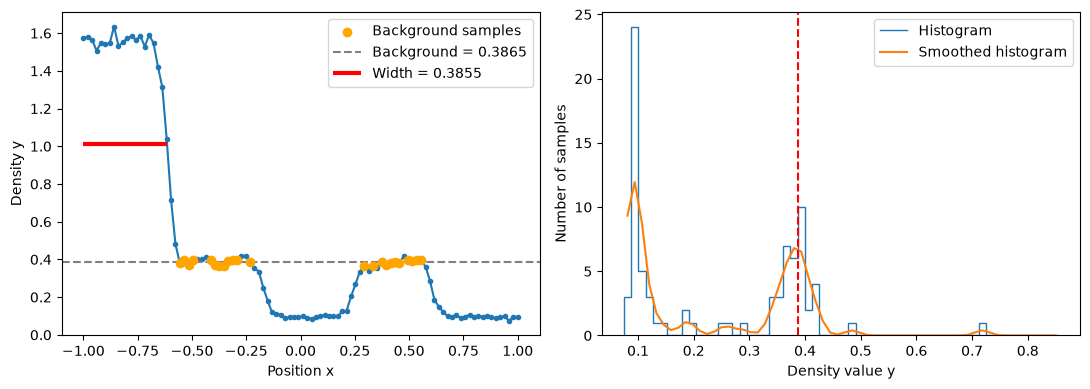

Candidate lower-density modes: [0.10777917 0.45717917]
Selected background: 0.45775
Peak width: 0.13229505963269206


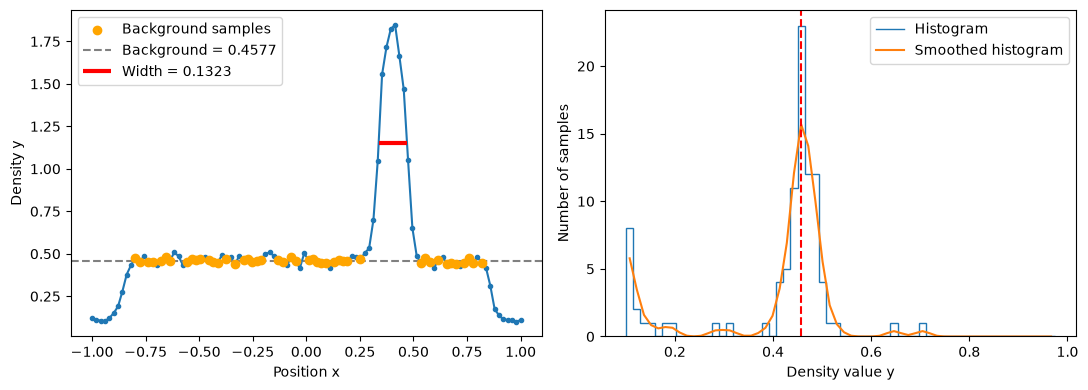

Candidate lower-density modes: [0.10447292 0.42522708]
Selected background: 0.4285
Peak width: 0.22042672710225591


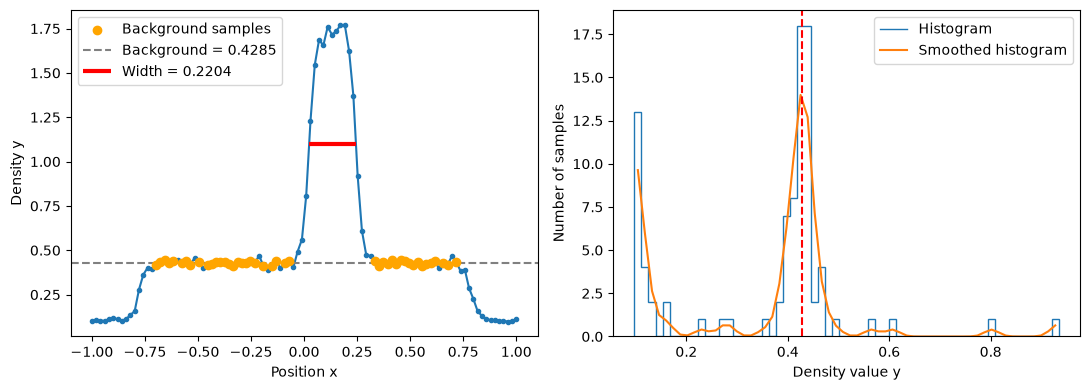

Candidate lower-density modes: [0.0839375 0.3800625]
Selected background: 0.381
Peak width: 0.3843599410600175


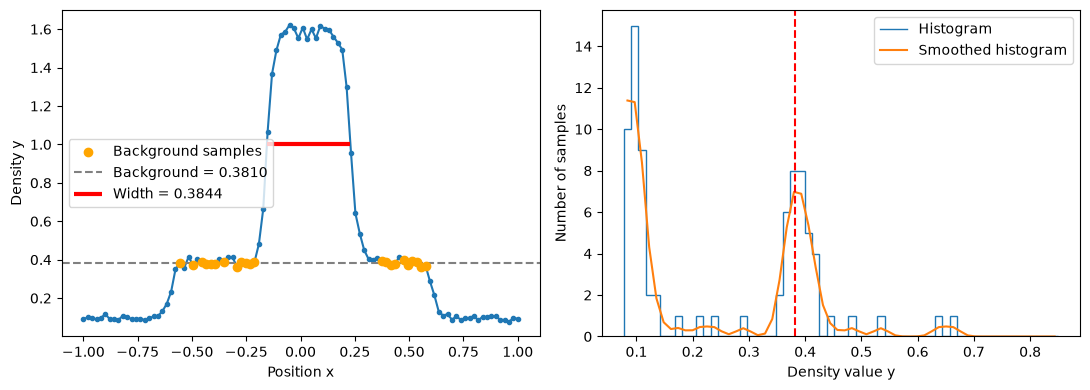

Candidate lower-density modes: [0.1115125 0.4420625]
Selected background: 0.445
Peak width: 0.1287637367943294


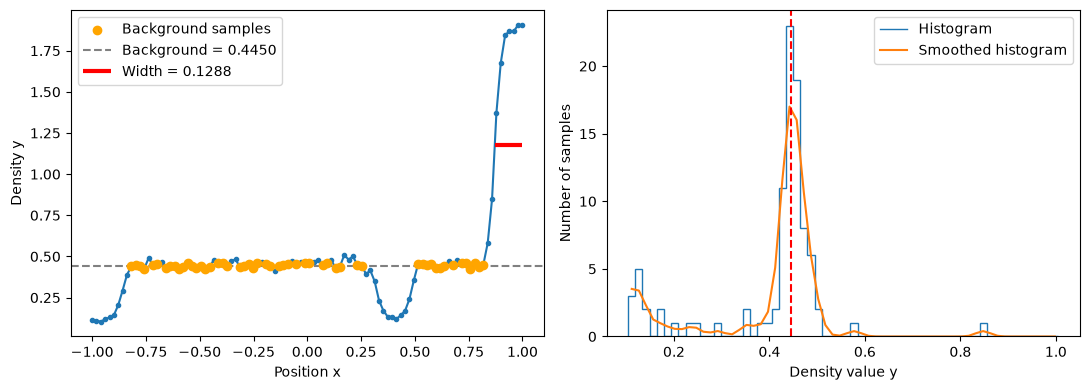

Candidate lower-density modes: [0.10527917 0.44012083]
Selected background: 0.44125000000000003
Peak width: 0.19814178288754536


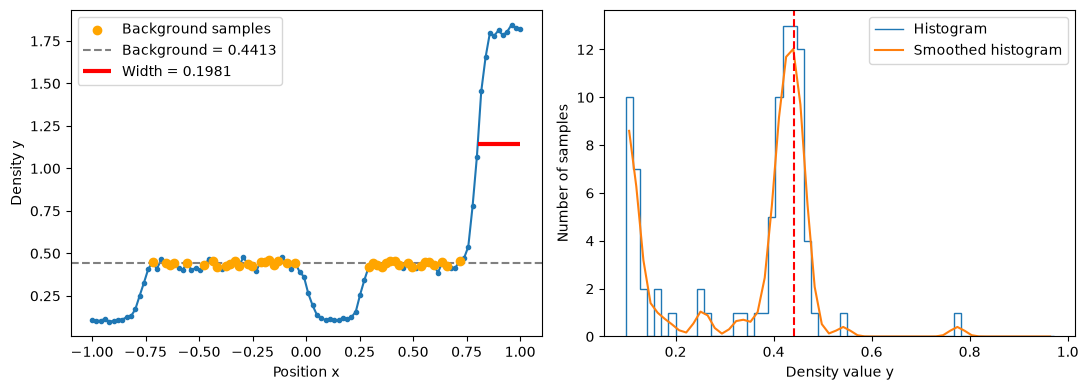

Candidate lower-density modes: [0.08866667 0.382     ]
Selected background: 0.386
Peak width: 0.3793245809594582


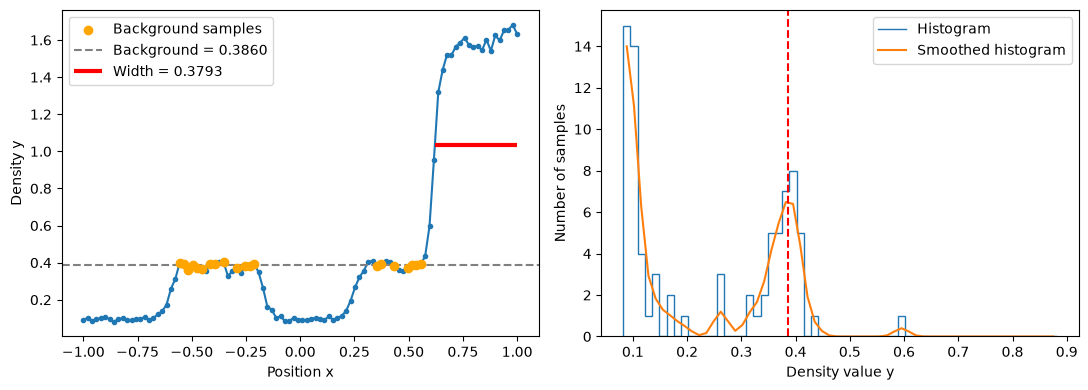

In [117]:
for ps_selected in (aps_selected, bps_selected, cps_selected):
    for c_val, ind in zip(cs_selected, (0,1,2)):
        y = ps_selected[ind][-1]
        import matplotlib.pyplot as plt

        background, mask, hist = histogram_background(y)

        result = peak_width(
            x, y,
            background=background,
            bounds=(-1.0, 1.0),
        )

        print("Candidate lower-density modes:", hist["modes"])
        print("Selected background:", background)
        print("Peak width:", result["width"])

        fig, axes = plt.subplots(1, 2, figsize=(11, 4))

        axes[0].plot(x, y, ".-")
        axes[0].scatter(
            x[mask], y[mask], color="orange", zorder=3,
            label="Background samples",
        )
        axes[0].axhline(
            background, color="gray", ls="--",
            label=f"Background = {background:.4f}",
        )
        axes[0].hlines(
            result["level"], result["left"], result["right"],
            color="red", lw=3,
            label=f"Width = {result['width']:.4f}",
        )
        axes[0].legend()
        axes[0].set_xlabel("Position x")
        axes[0].set_ylabel("Density y")

        axes[1].stairs(hist["counts"], hist["edges"], label="Histogram")
        axes[1].plot(
            hist["centers"], hist["smoothed"], label="Smoothed histogram"
        )
        axes[1].axvline(background, color="red", ls="--")
        axes[1].set_xlabel("Density value y")
        axes[1].set_ylabel("Number of samples")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

In [122]:
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks


def histogram_background(
    y, *, bins=60, smooth=1.0, prominence=0.12, min_height=0.15
):
    y = np.asarray(y, dtype=float)

    if y.ndim != 1 or y.size < 5:
        raise ValueError("Expected a 1D array with at least 5 samples.")
    if not np.all(np.isfinite(y)) or np.ptp(y) == 0:
        raise ValueError("Data must be finite and nonconstant.")
    if smooth <= 0:
        raise ValueError("smooth must be positive.")

    cutoff = y.min() + 0.5 * np.ptp(y)
    lower = y[y < cutoff]

    counts, edges = np.histogram(
        lower, bins=bins, range=(y.min(), cutoff)
    )
    centers = 0.5 * (edges[:-1] + edges[1:])
    filtered = gaussian_filter1d(counts.astype(float), sigma=smooth)

    padded = np.r_[0.0, filtered, 0.0]
    peaks, _ = find_peaks(
        padded,
        prominence=prominence * filtered.max(),
        height=min_height * filtered.max(),
    )
    peaks = peaks - 1
    peaks = peaks[(peaks >= 0) & (peaks < len(counts))]

    if peaks.size < 2:
        raise ValueError(
            "Need at least two significant modes to distinguish "
            "the lowest level from the intermediate background."
        )

    radius = max(1, int(np.ceil(smooth)))

    def estimate_level(peak):
        lo = max(0, peak - radius)
        hi = min(len(counts) - 1, peak + radius)

        mask = (y >= edges[lo]) & (y < edges[hi + 1])
        level = np.median(y[mask])

        return level, mask

    lowest, lowest_mask = estimate_level(peaks[0])
    background, background_mask = estimate_level(peaks[-1])

    diagnostics = {
        "counts": counts,
        "edges": edges,
        "centers": centers,
        "smoothed": filtered,
        "modes": centers[peaks],
        "cutoff": cutoff,
        "lowest_mask": lowest_mask,
        "background_mask": background_mask,
    }

    return background, lowest, diagnostics

Intermediate background: 0.45600
Lowest density level:   0.12550
Peak width:             0.12847


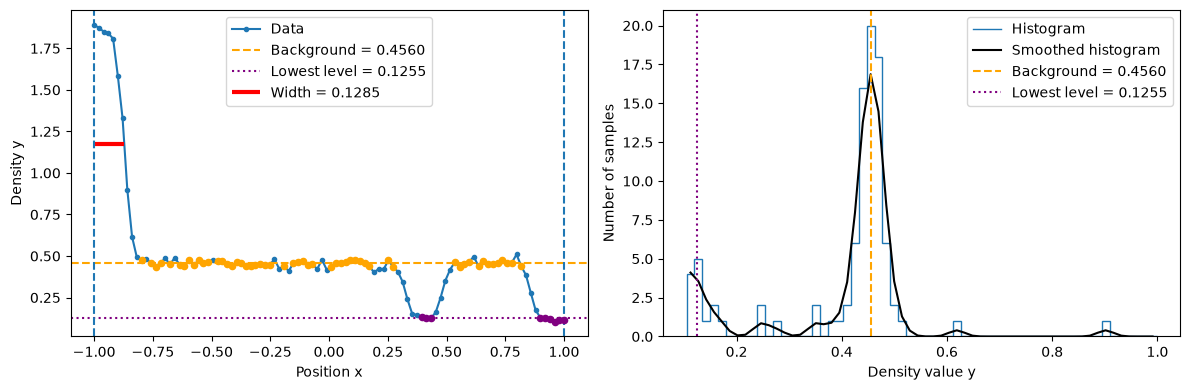

Intermediate background: 0.43200
Lowest density level:   0.11000
Peak width:             0.21149


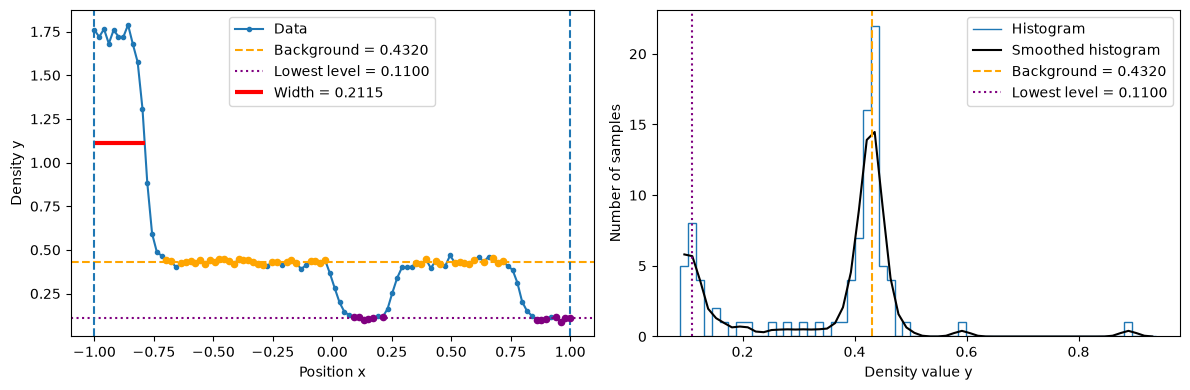

Intermediate background: 0.38650
Lowest density level:   0.09625
Peak width:             0.38550


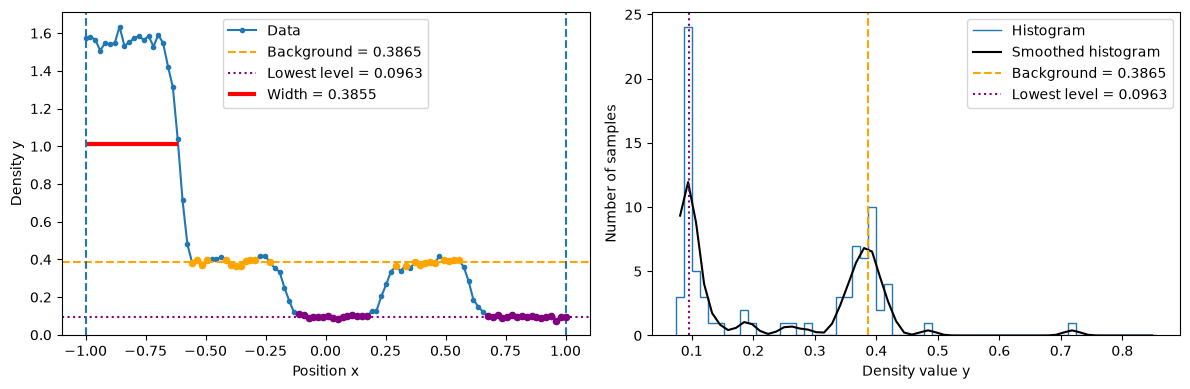

Intermediate background: 0.45775
Lowest density level:   0.11000
Peak width:             0.13230


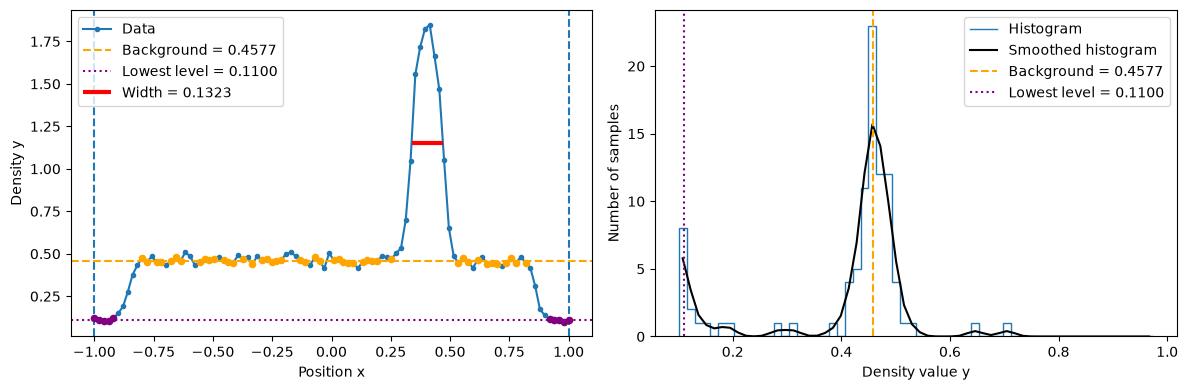

Intermediate background: 0.42850
Lowest density level:   0.10650
Peak width:             0.22043


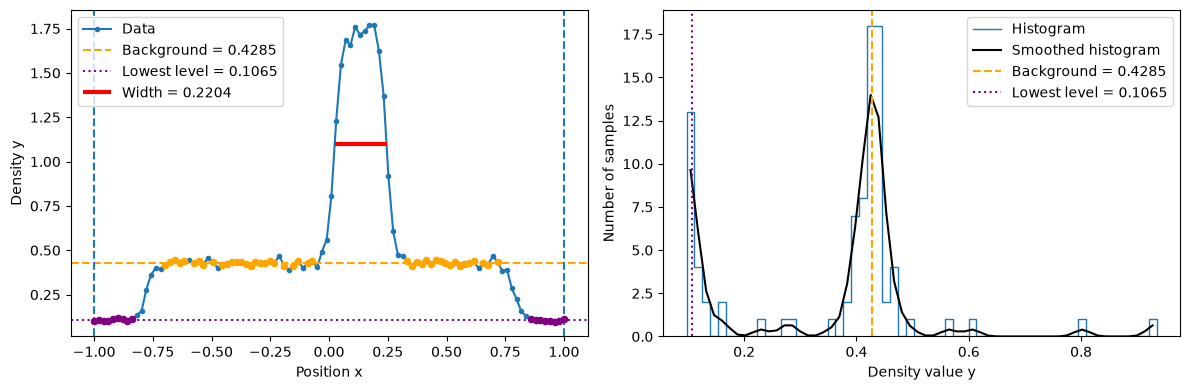

Intermediate background: 0.38100
Lowest density level:   0.09100
Peak width:             0.38436


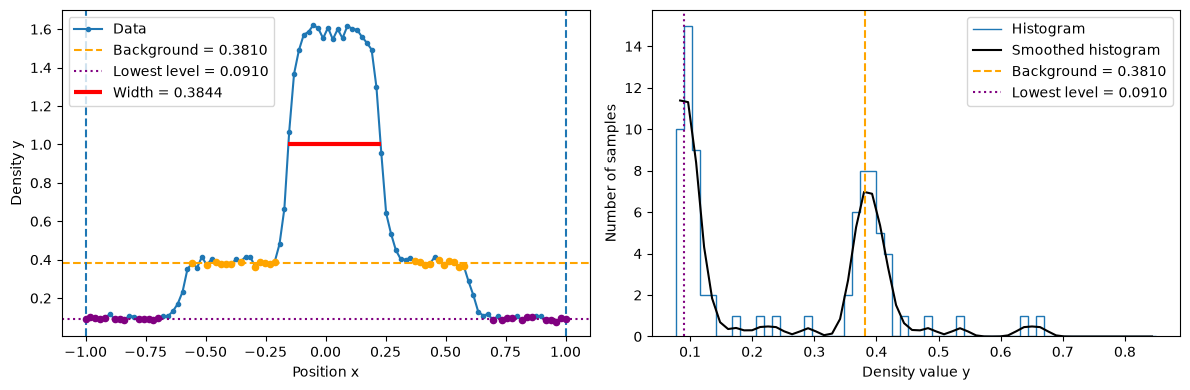

Intermediate background: 0.44500
Lowest density level:   0.12000
Peak width:             0.12876


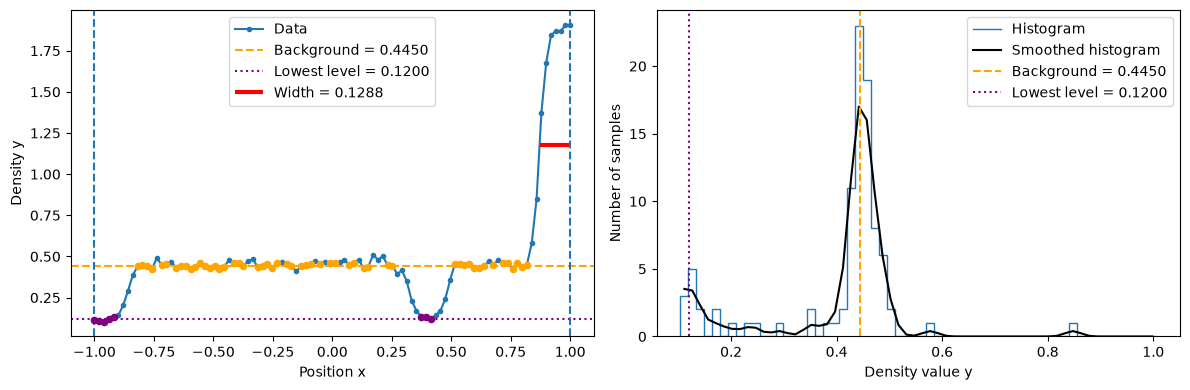

Intermediate background: 0.44125
Lowest density level:   0.11050
Peak width:             0.19814


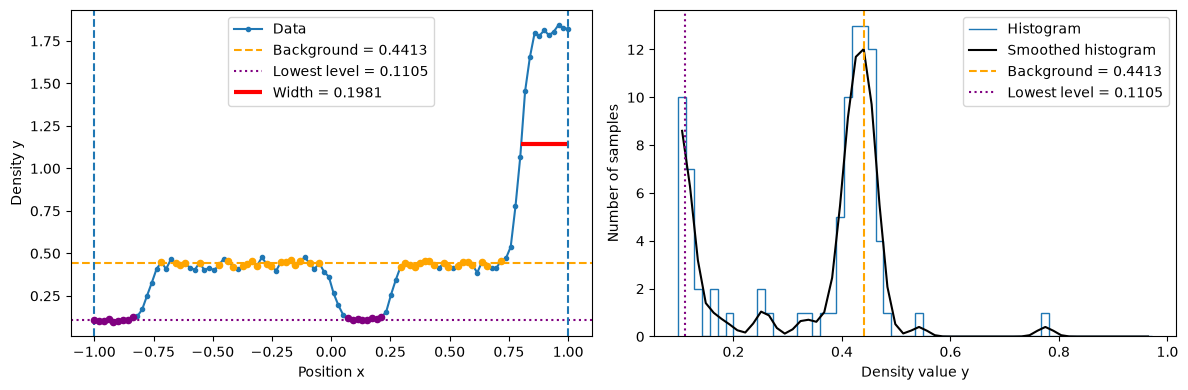

Intermediate background: 0.38600
Lowest density level:   0.09450
Peak width:             0.37932


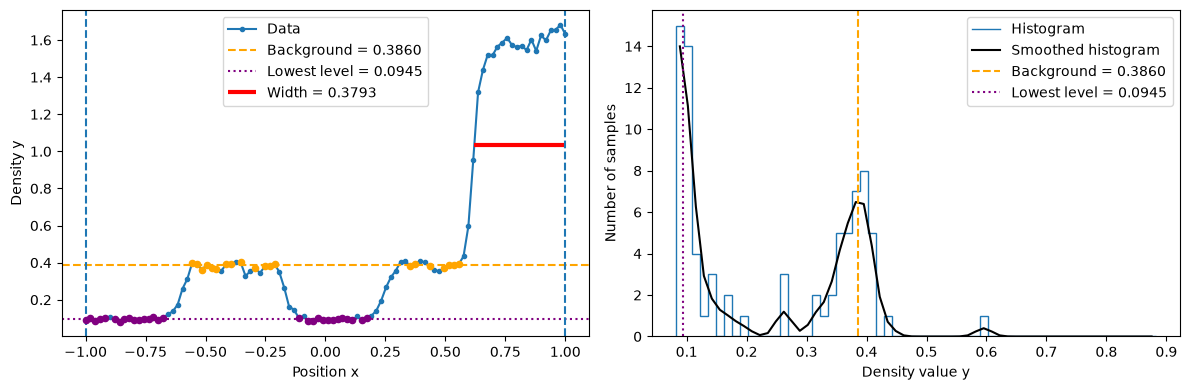

In [ ]:
import matplotlib.pyplot as plt

for ps_selected in (aps_selected, bps_selected, cps_selected):
    for c_val, ind in zip(cs_selected, (0,1,2)):
        y = ps_selected[ind][-1]
        background, lowest, hist = histogram_background(y)

        result = peak_width(
            x, y,
            background=background,
            bounds=(-1.0, 1.0),
        )

        print(f"Intermediate background: {background:.5f}")
        print(f"Lowest density level:   {lowest:.5f}")
        print(f"Peak width:             {result['width']:.5f}")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        # Spatial profile
        ax = axes[0]
        ax.plot(x, y, ".-", label="Data")

        ax.scatter(
            x[hist["background_mask"]],
            y[hist["background_mask"]],
            color="orange", s=20, zorder=3,
        )
        ax.scatter(
            x[hist["lowest_mask"]],
            y[hist["lowest_mask"]],
            color="purple", s=20, zorder=3,
        )

        ax.axhline(
            background, color="orange", ls="--",
            label=f"Background = {background:.4f}",
        )
        ax.axhline(
            lowest, color="purple", ls=":",
            label=f"Lowest level = {lowest:.4f}",
        )
        ax.hlines(
            result["level"], result["left"], result["right"],
            color="red", lw=3,
            label=f"Width = {result['width']:.4f}",
        )

        ax.set_xlabel("Position x")
        ax.set_ylabel("Density y")
        ax.legend()

        # Histogram of density values
        ax = axes[1]
        ax.stairs(hist["counts"], hist["edges"], label="Histogram")
        ax.plot(
            hist["centers"], hist["smoothed"],
            color="black", label="Smoothed histogram",
        )
        ax.axvline(
            background, color="orange", ls="--",
            label=f"Background = {background:.4f}",
        )
        ax.axvline(
            lowest, color="purple", ls=":",
            label=f"Lowest level = {lowest:.4f}",
        )

        ax.set_xlabel("Density value y")
        ax.set_ylabel("Number of samples")
        ax.legend()

        plt.tight_layout()
        plt.show()

Intermediate background: 0.45600
Lowest density level:   0.12550
Peak width:             0.12847


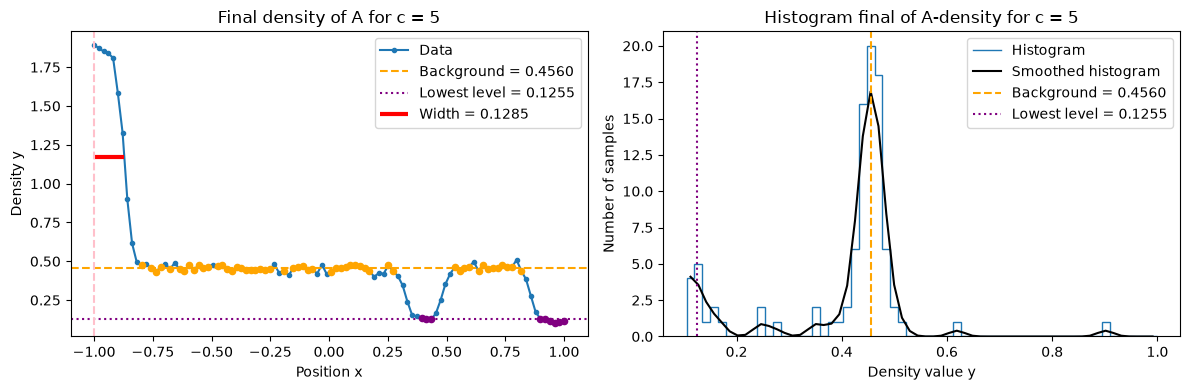

Intermediate background: 0.44350
Lowest density level:   0.11375
Peak width:             0.15208


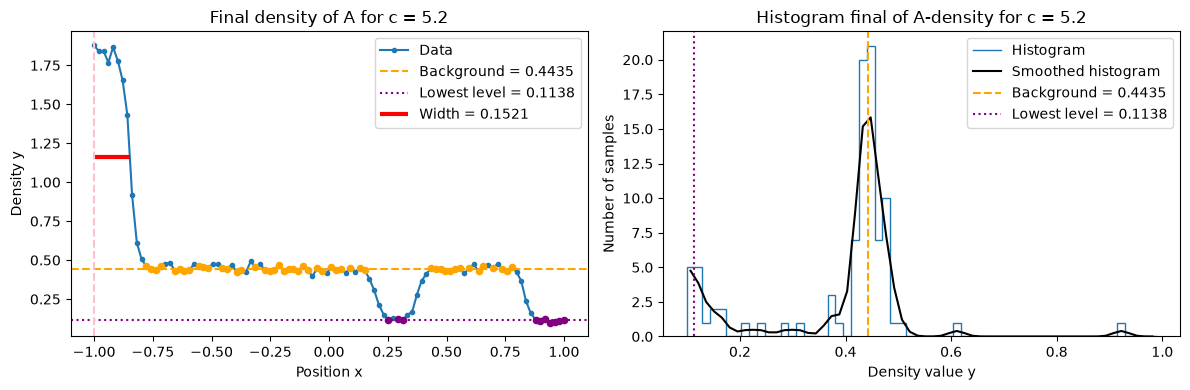

Intermediate background: 0.44400
Lowest density level:   0.11350
Peak width:             0.16440


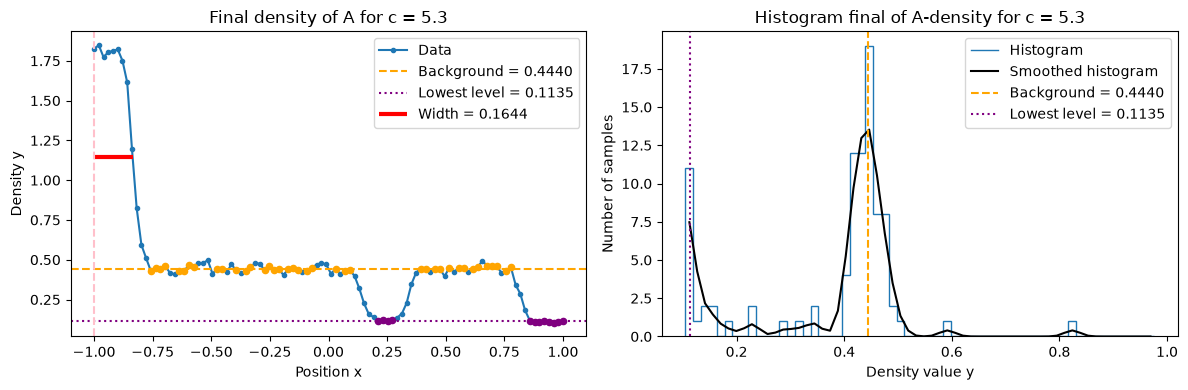

Intermediate background: 0.43700
Lowest density level:   0.10900
Peak width:             0.16612


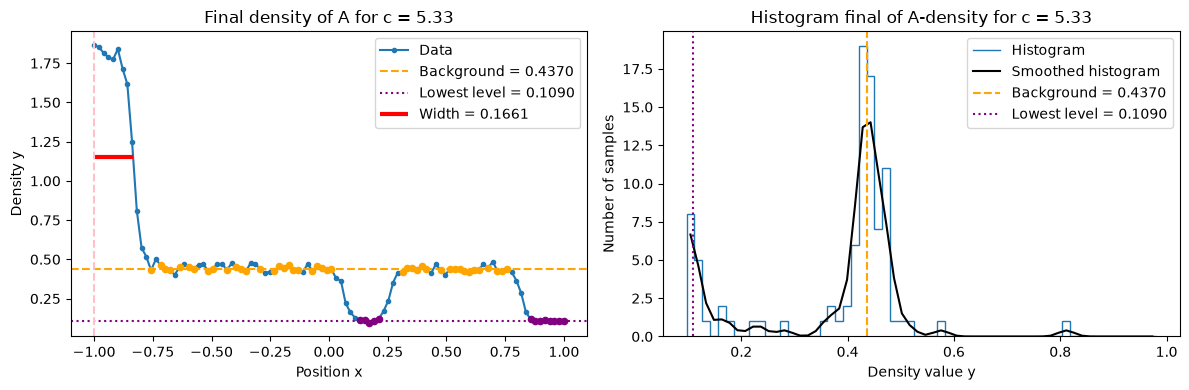

Intermediate background: 0.43950
Lowest density level:   0.10975
Peak width:             0.19510


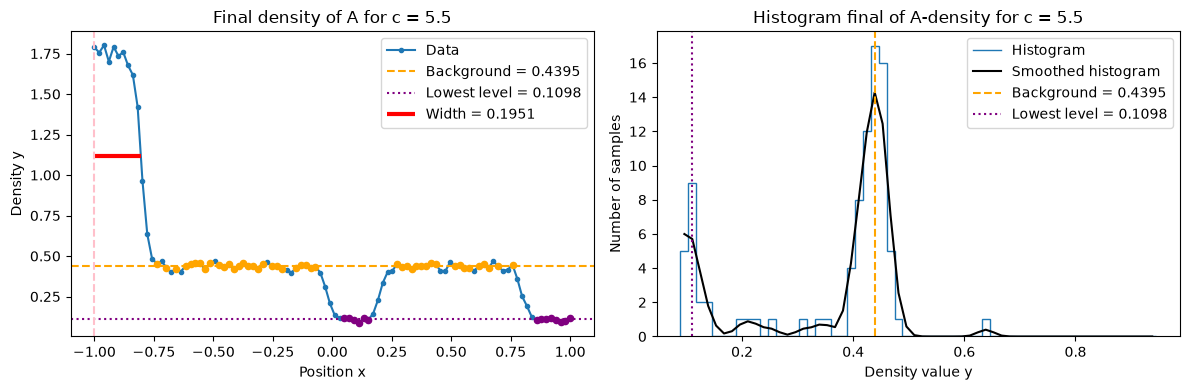

Intermediate background: 0.43200
Lowest density level:   0.11000
Peak width:             0.21149


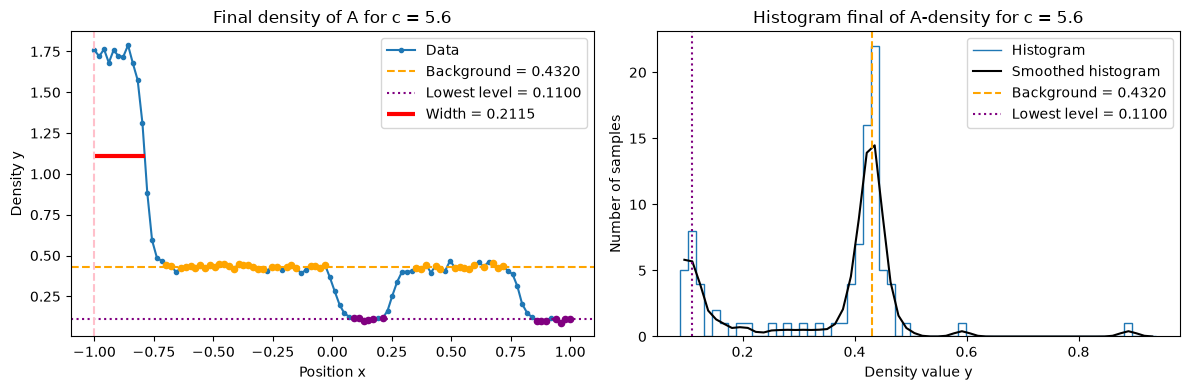

Intermediate background: 0.41250
Lowest density level:   0.10575
Peak width:             0.25824


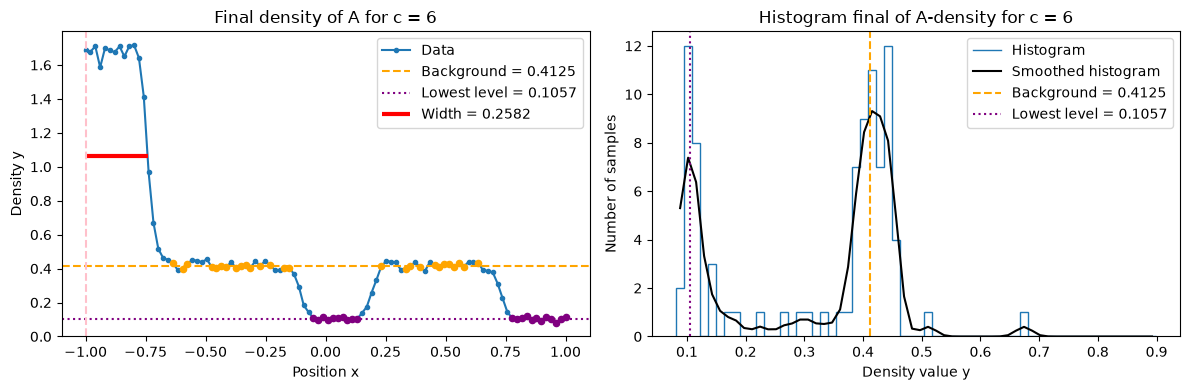

Intermediate background: 0.38650
Lowest density level:   0.09625
Peak width:             0.38550


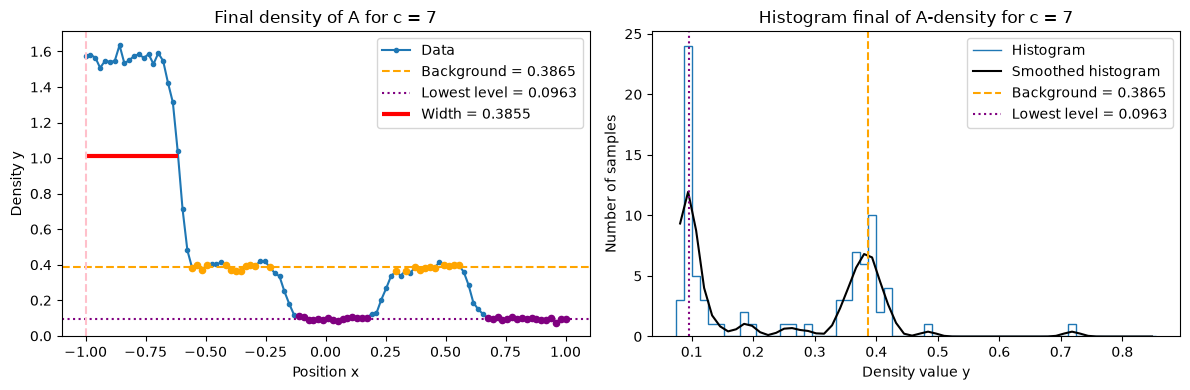

Intermediate background: 0.45775
Lowest density level:   0.11000
Peak width:             0.13230


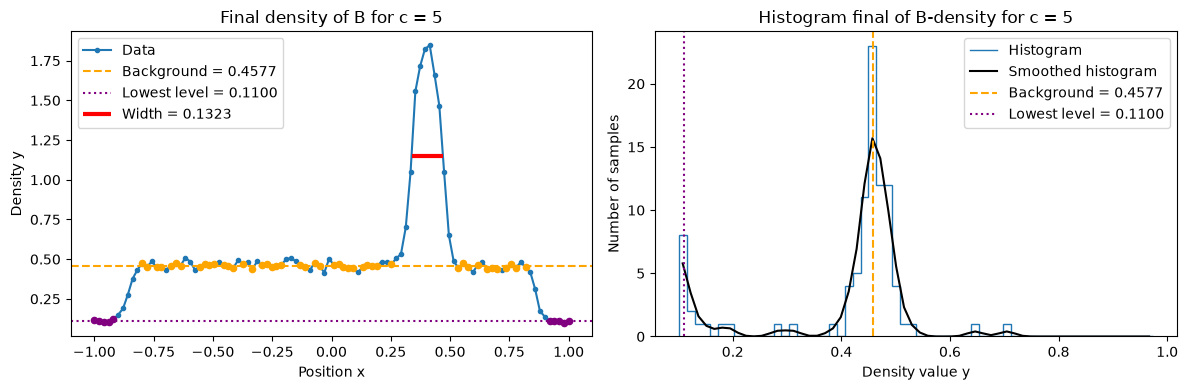

Intermediate background: 0.45125
Lowest density level:   0.10950
Peak width:             0.15495


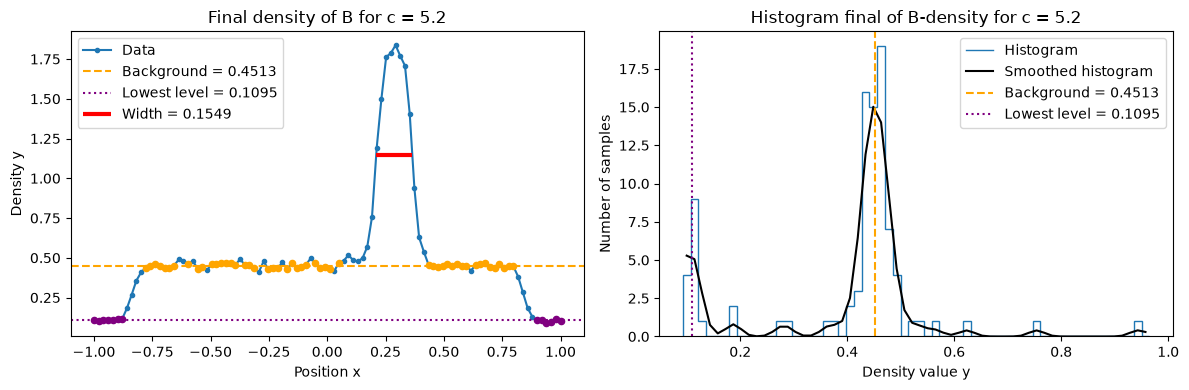

Intermediate background: 0.44425
Lowest density level:   0.10550
Peak width:             0.17259


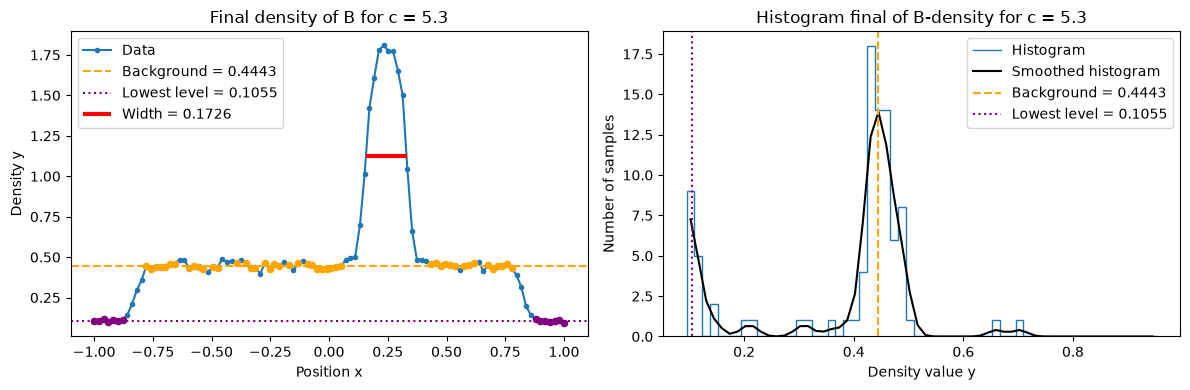

Intermediate background: 0.45000
Lowest density level:   0.10575
Peak width:             0.17001


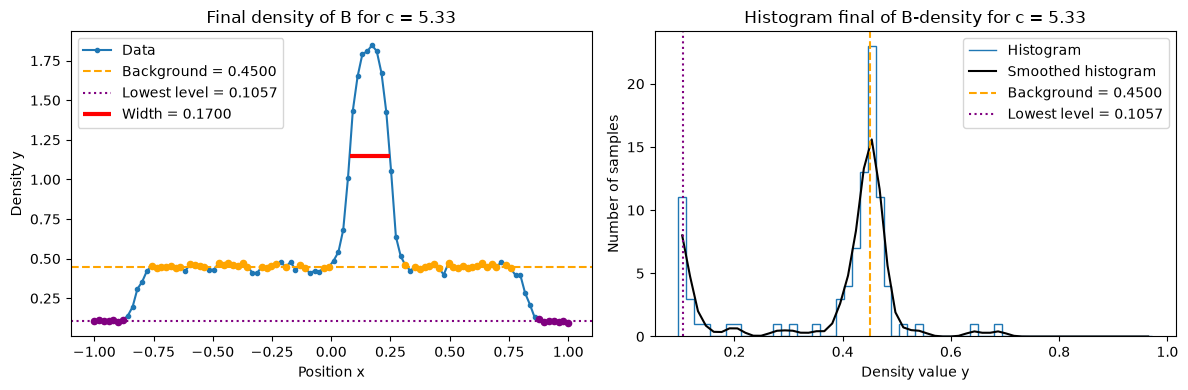

Intermediate background: 0.43500
Lowest density level:   0.10850
Peak width:             0.20038


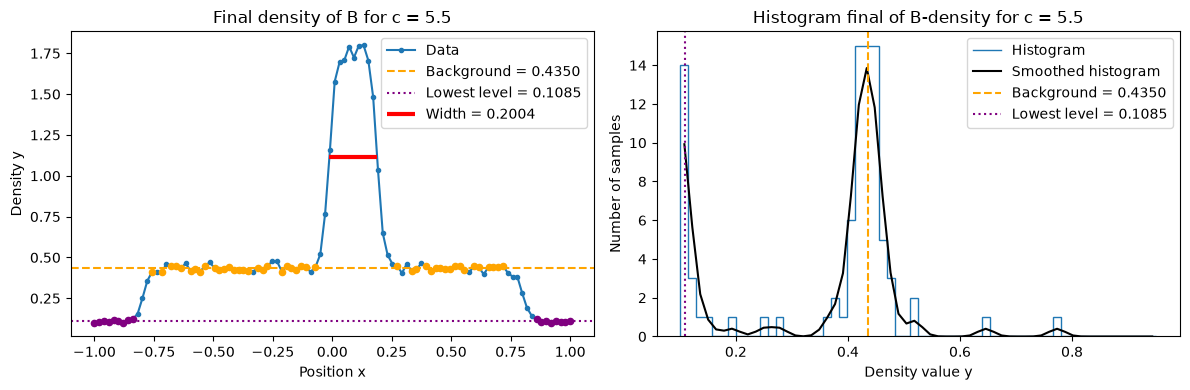

Intermediate background: 0.42850
Lowest density level:   0.10650
Peak width:             0.22043


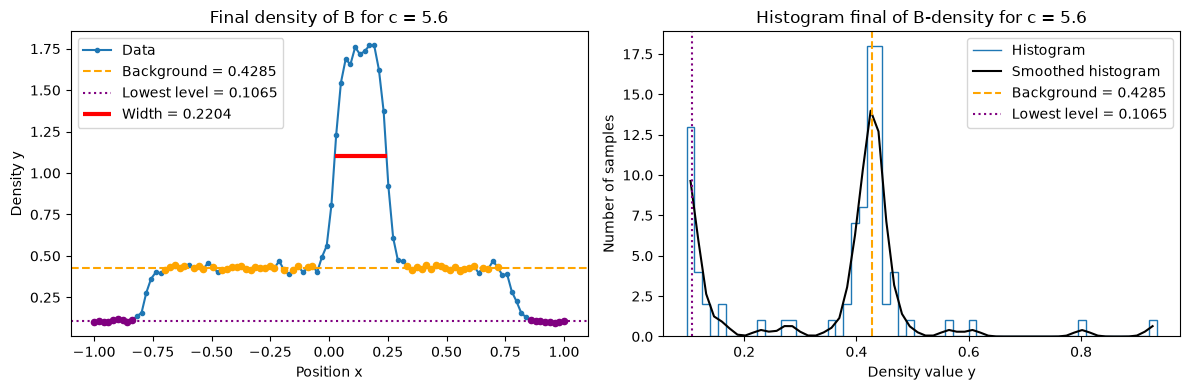

Intermediate background: 0.41000
Lowest density level:   0.10450
Peak width:             0.27072


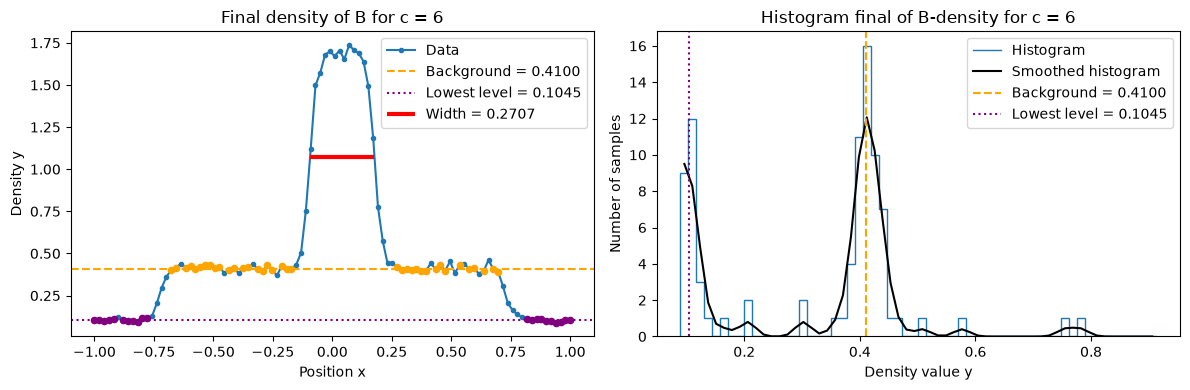

Intermediate background: 0.38100
Lowest density level:   0.09100
Peak width:             0.38436


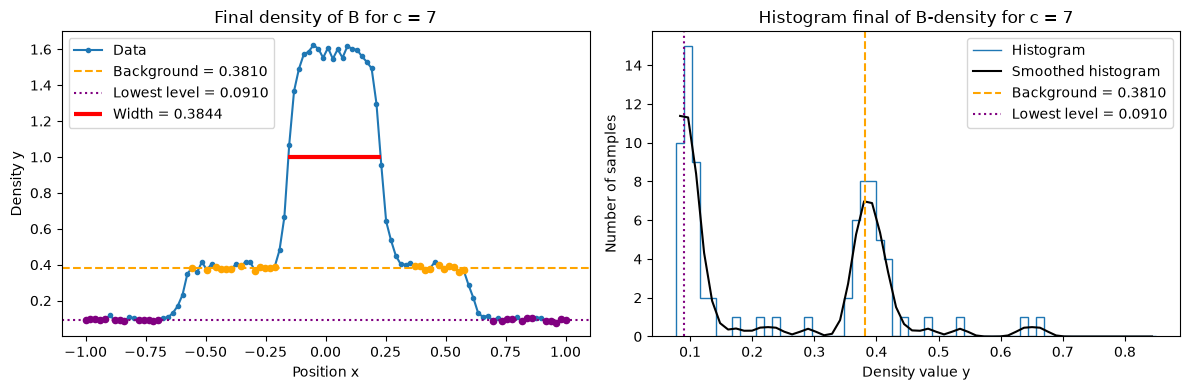

Intermediate background: 0.44500
Lowest density level:   0.12000
Peak width:             0.12876


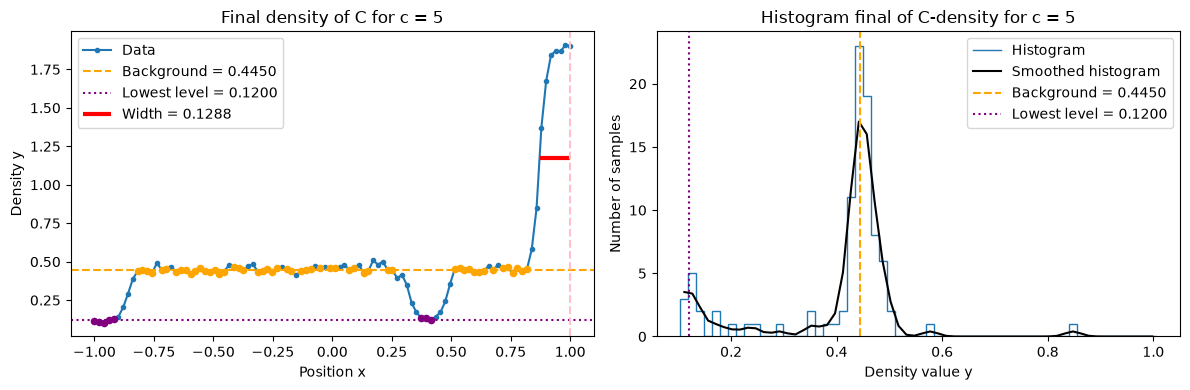

Intermediate background: 0.44150
Lowest density level:   0.11325
Peak width:             0.15087


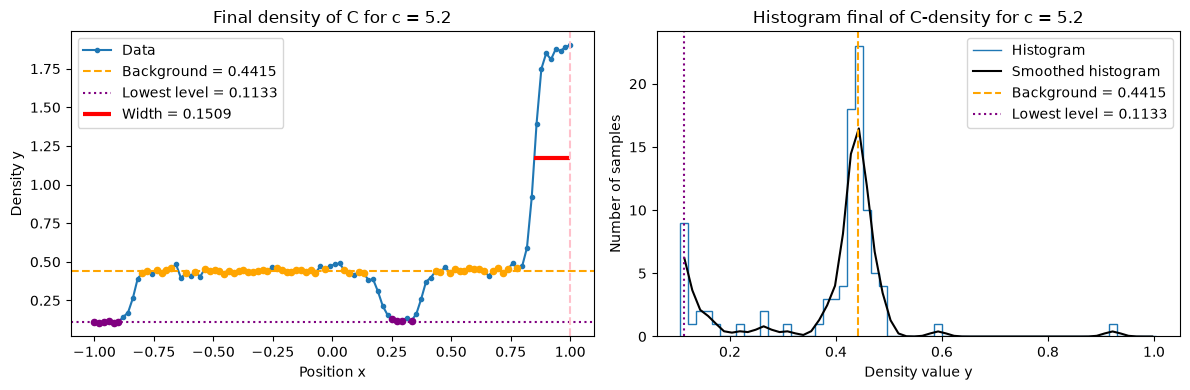

Intermediate background: 0.43150
Lowest density level:   0.11350
Peak width:             0.16536


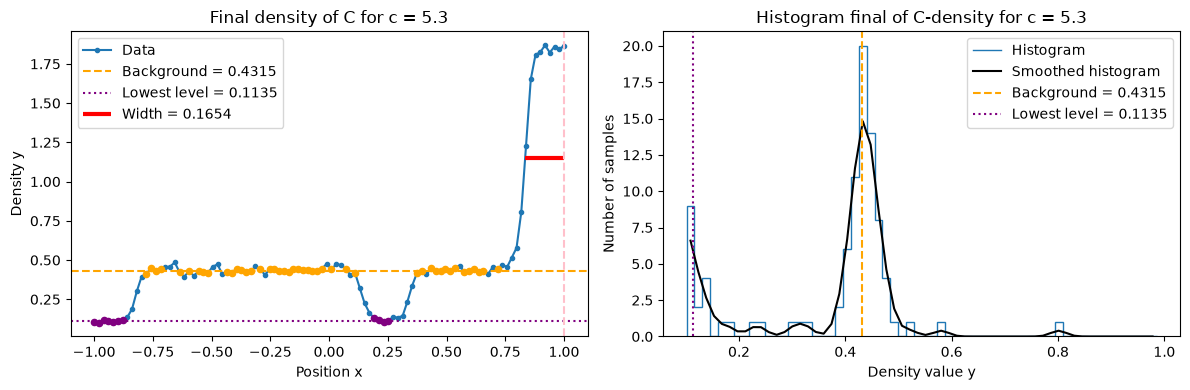

Intermediate background: 0.43600
Lowest density level:   0.11025
Peak width:             0.16719


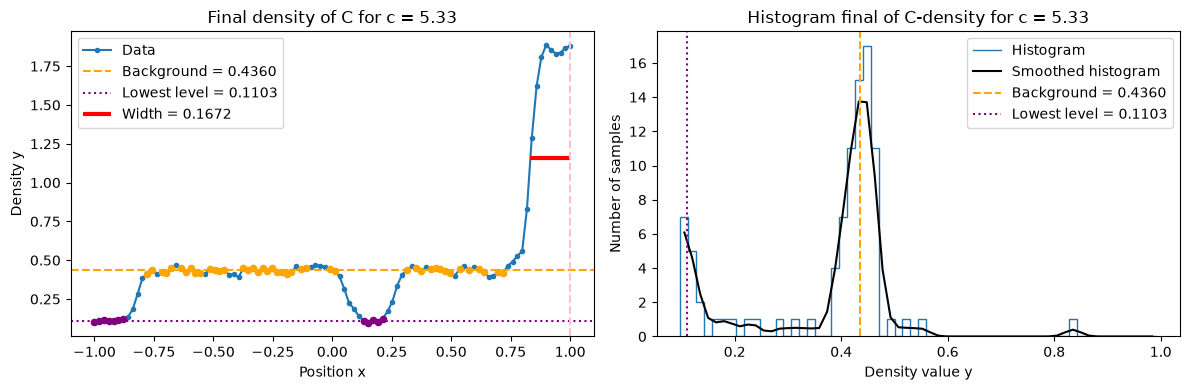

Intermediate background: 0.43800
Lowest density level:   0.10600
Peak width:             0.18548


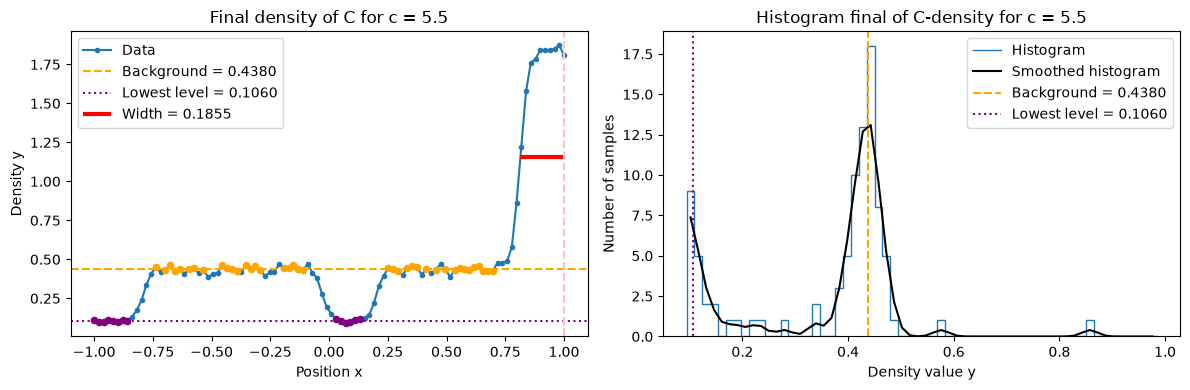

Intermediate background: 0.44125
Lowest density level:   0.11050
Peak width:             0.19814


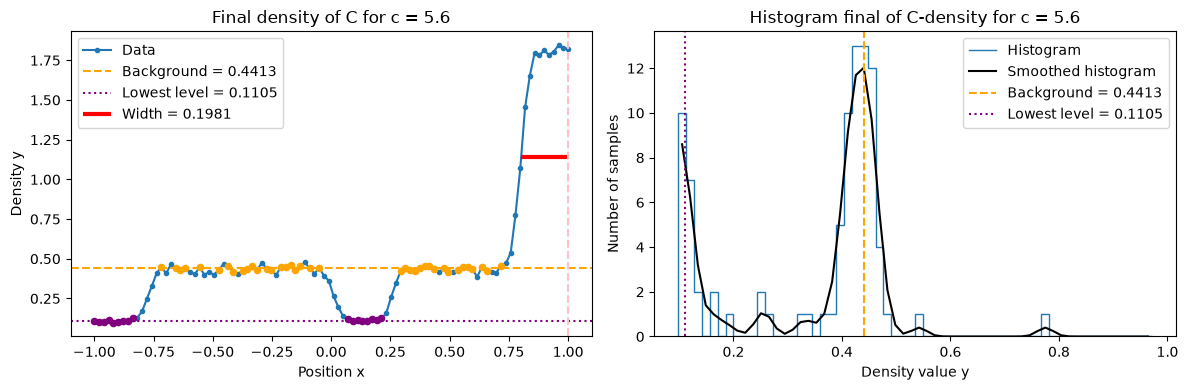

Intermediate background: 0.41100
Lowest density level:   0.10300
Peak width:             0.25658


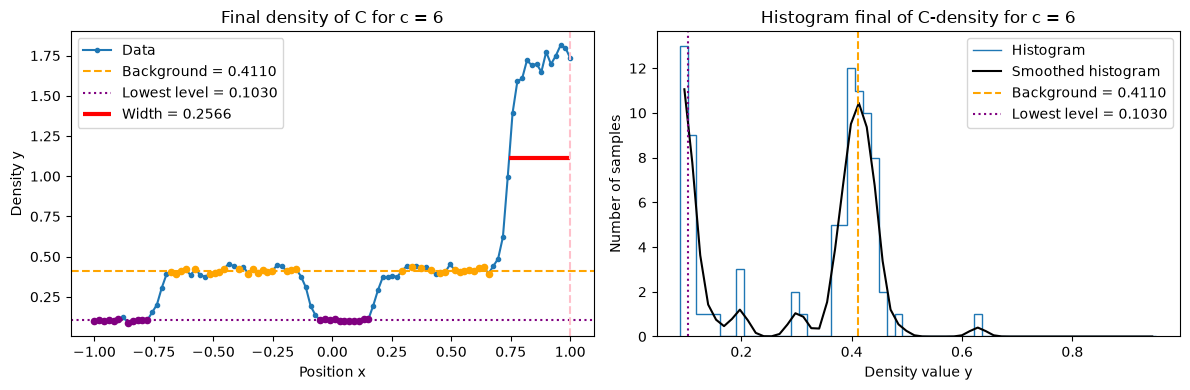

Intermediate background: 0.38600
Lowest density level:   0.09450
Peak width:             0.37932


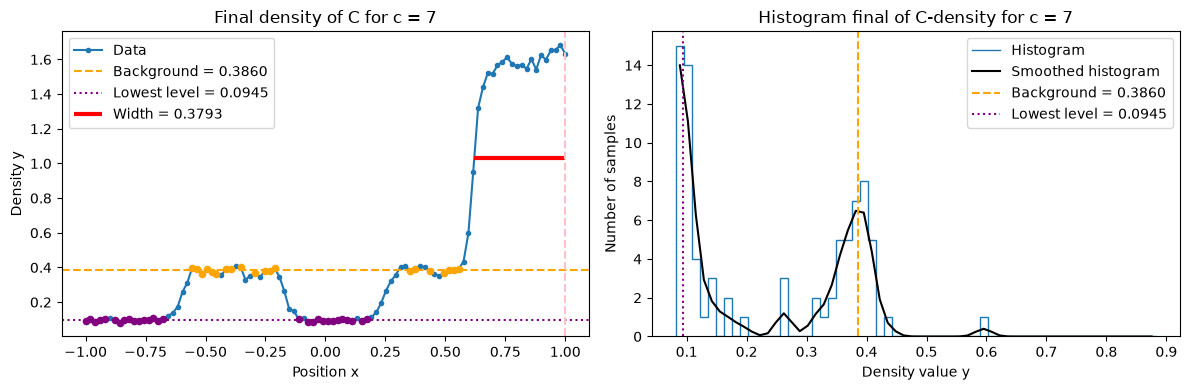

In [ ]:
final_ws = []
final_w_errors = []
final_ells = []
final_ell_errors = []
for ps, peak_position in ((all_a_ps[2:], "left"), (all_b_ps[2:], "center"), (all_c_ps[2:], "right")):
    for ind, c_val in enumerate(c_vals[2:]):
        ells = []
        ws = []
        for y in ps[ind]:
            background, lowest, hist = histogram_background(y)

            result = peak_width(
                x, y,
                background=background,
                bounds=(-1.0, 1.0),
            )

            ells.append(lowest)
            ws.append(result["width"])

            print(f"Intermediate background: {background:.5f}")
            print(f"Lowest density level:   {lowest:.5f}")
            print(f"Peak width:             {result['width']:.5f}")

            fig, axes = plt.subplots(1, 2, figsize=(12, 4))

            # Spatial profile
            ax = axes[0]
            ax.plot(x, y, ".-", label="Data")

            ax.scatter(
                x[hist["background_mask"]],
                y[hist["background_mask"]],
                color="orange", s=20, zorder=3,
            )
            ax.scatter(
                x[hist["lowest_mask"]],
                y[hist["lowest_mask"]],
                color="purple", s=20, zorder=3,
            )

            ax.axhline(
                background, color="orange", ls="--",
                label=f"Background = {background:.4f}",
            )
            ax.axhline(
                lowest, color="purple", ls=":",
                label=f"Lowest level = {lowest:.4f}",
            )
            ax.hlines(
                result["level"], result["left"], result["right"],
                color="red", lw=3,
                label=f"Width = {result['width']:.4f}",
            )

            match peak_position:
                case "left":
                    ax.axvline(-1, ls="--", color="pink")
                    species = "A"
                case "center":
                    species = "B"
                case "right":
                    ax.axvline(1, ls="--", color="pink")
                    species = "C"
                    
            ax.set_title(f"Final density of {species} for c = {c_val}")
            
            ax.set_xlabel("Position x")
            ax.set_ylabel("Density y")
            ax.legend()

            # Histogram of density values
            ax = axes[1]

            ax.set_title(f"Histogram final of {species}-density for c = {c_val}")

            ax.stairs(hist["counts"], hist["edges"], label="Histogram")
            ax.plot(
                hist["centers"], hist["smoothed"],
                color="black", label="Smoothed histogram",
            )
            ax.axvline(
                background, color="orange", ls="--",
                label=f"Background = {background:.4f}",
            )
            ax.axvline(
                lowest, color="purple", ls=":",
                label=f"Lowest level = {lowest:.4f}",
            )

            ax.set_xlabel("Density value y")
            ax.set_ylabel("Number of samples")
            ax.legend()

            plt.tight_layout()
            plt.show()

    ell = np.mean(ells)
    ell_error = np.std(ell) / np.sqrt(len(ells))
    w = np.mean(ws)
    w_error = np.std(ws) / np.sqrt(len(ws))
    final_ells.appen(ell)
    final_ell_errors.append(ell_error)
    final_ws.append(w)
    final_w_errors.append(w_error)

plt.error(c_vals[2:], final_ws, yerr=final_w_errors) 


In [11]:
def hist_of_hist(p, n_bins=100):
    H, bins = np.histogram(p, bins=n_bins, range=(0,2))
    centers = [(bins[j] + bins[j-1])/2 for j in range(1,len(bins))]
    bin_width = 2 / n_bins
    return centers, H, bin_width

In [12]:
aps_selected = [all_a_ps[2], all_a_ps[7], all_a_ps[-1]]

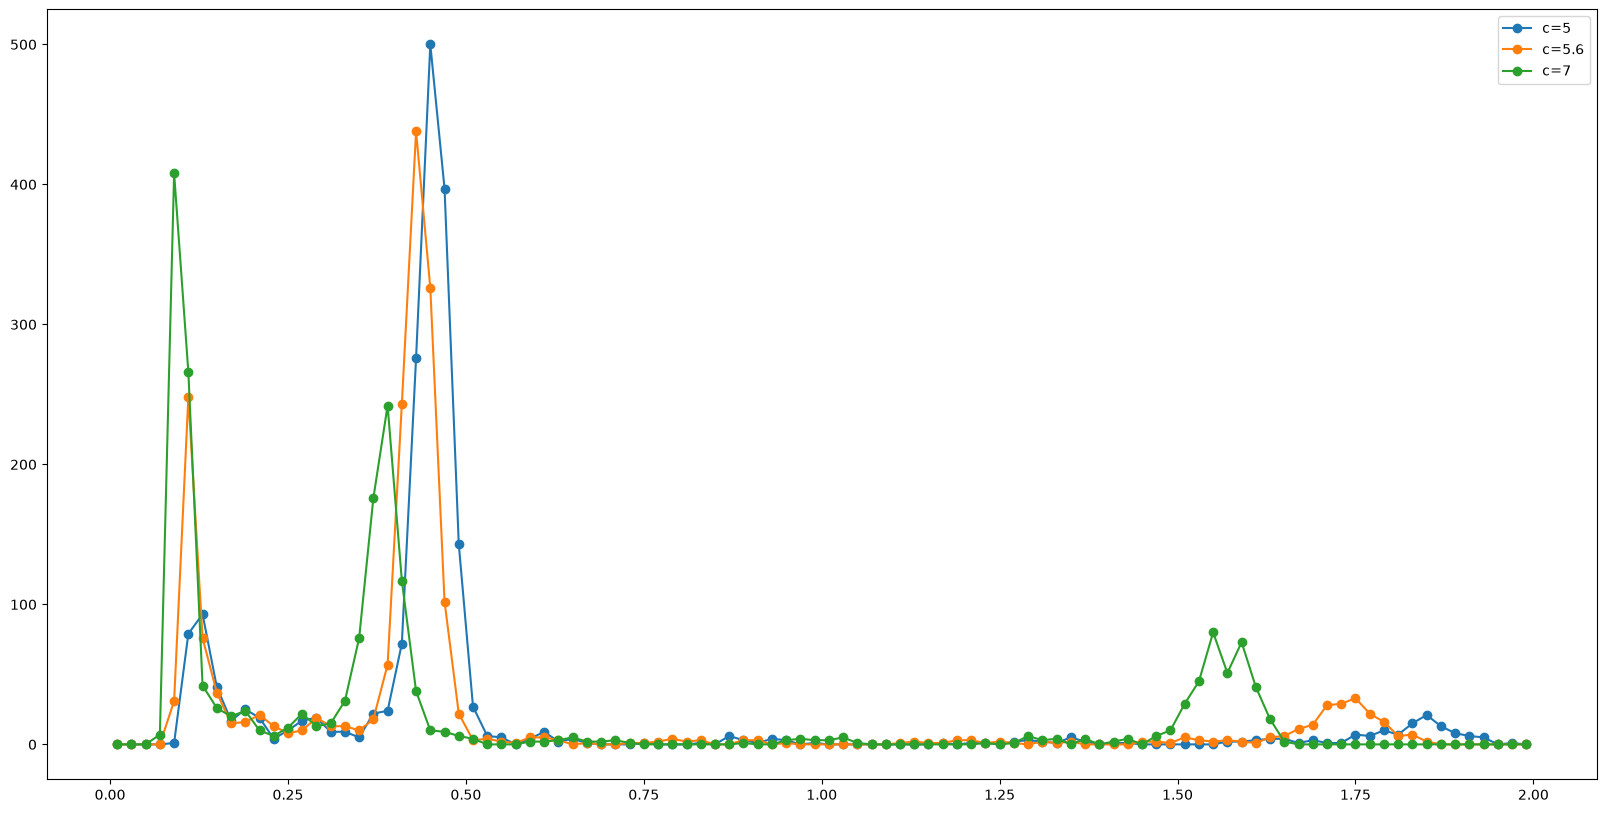

In [13]:
Hs, centerss = [], []
fig, ax = plt.subplots(figsize=(20,10))
for ap, c in zip(aps_selected, cs_selected):
    centers, H, _ = hist_of_hist(ap)
    Hs.append(H)
    centerss.append(centers)
    ax.plot(centers, H, "-o", label=f"c={c}")
plt.legend()
plt.show()

In [14]:
for H, centers in zip(Hs, centerss):
    inds = find_peaks(H, threshold=10)[0]
    for i in inds:
        print(centers[i])
    print("")
    

0.13
0.45

0.11
0.43

0.09
0.39
1.55
1.59



In [15]:
find_peaks(H, distance=12)

(array([ 4, 19, 32, 51, 64, 77]), {})

In [16]:
centers[11]

np.float64(0.22999999999999998)

In [17]:
centers[23]

np.float64(0.47)

In [18]:
centers[46]

np.float64(0.93)

In [59]:
def get_spreads(density):
    # calculate rolling spread
    spreads = []
    for ind in range(3, len(density) - 3):
        slice = density[ind - 3 : ind + 3]
        spread = max(slice) - min(slice)
        spreads.append(spread)
    return spreads


def get_level_widths(density):
    spreads = get_spreads(density)
    # indices = np.where(np.isin(spreads, maxima))
    # indices = [spreads.index(maximum) for maximum in maxima]
    # indices = argrelextrema(np.array(spreads), np.greater, order=6)[0]
    indices = find_peaks(spreads)[0]
    print("peaks:\n")
    plt.plot(spreads)
    print(f"indices: {indices}")
    # remove fake interfaces with too little density jumps
    for ind, index in enumerate(indices):
        slice = spreads[index - 3 : index + 3]
        if max(slice) - min(slice) < 0.2:
            indices = np.delete(indices, ind)
    if len(indices) != 4:
        print(f"indices: {indices}")
        plt.plot(spreads)
        plt.show()
        raise ValueError(f"Interfaces must be 4, got {len(indices)}")

    low_p = np.mean(np.concatenate([density[: indices[0]], density[indices[-1] :]]))
    print(f"Low density: l = {low_p}")

    high_width = (indices[2] - indices[1]) * BIN_WIDTH
    middle_width = (indices[1] - indices[0] + indices[3] - indices[2]) * BIN_WIDTH
    low_width = (indices[0] + 100 - indices[3]) * BIN_WIDTH

    return high_width, middle_width, low_width, spreads

In [60]:
def peak_width_analytical(c, low_level=0.1):
    h = low_level + 1 / (c * low_level)
    En = h * (1 + 4 * c * low_level**2)
    m = np.sinh((1 / 3) * np.arcsinh(3 * En * np.sqrt(3 * c))) / np.sqrt(3 * c)
    w = (1 - 2 * m) / (h + 2 * low_level - 3 * m)
    return w


---> Handling c=5

Handling species a
ell = 0.12666666666666668
w_theo: 0.16788659101778344
w_exp: 0.0
0.16788659101778344
Handling species b
ell = 0.11333333333333334
w_theo: 0.11810791673825262
w_exp: 0.14790511044825536
0.11810791673825262
Handling species c
ell = 0.11333333333333334
w_theo: 0.11810791673825262
w_exp: 0.010759493670886116
0.11810791673825262

---> Handling c=5.2

Handling species a
ell = 0.11333333333333334
w_theo: 0.15413777349050747
w_exp: 0.0
0.15413777349050747
Handling species b
ell = 0.11333333333333334
w_theo: 0.15413777349050747
w_exp: 0.16869352730648488
0.15413777349050747
Handling species c
ell = 0.11333333333333334
w_theo: 0.15413777349050747
w_exp: 0.0
0.15413777349050747

---> Handling c=5.3

Handling species a
ell = 0.11333333333333334
w_theo: 0.17256268647710019
w_exp: 0.0129333333333332
0.17256268647710019
Handling species b
ell = 0.1
w_theo: 0.11579833329810472
w_exp: 0.18854177050067988
0.11579833329810472
Handling species c
ell = 0.1133333333333

/tmp/ipykernel_867097/3014412059.py:18: PeakPropertyWarning: some peaks have a prominence of 0
  w_sim = peak_widths(p, [peak_ind])[0][0] * 0.02
/tmp/ipykernel_867097/3014412059.py:18: PeakPropertyWarning: some peaks have a width of 0
  w_sim = peak_widths(p, [peak_ind])[0][0] * 0.02


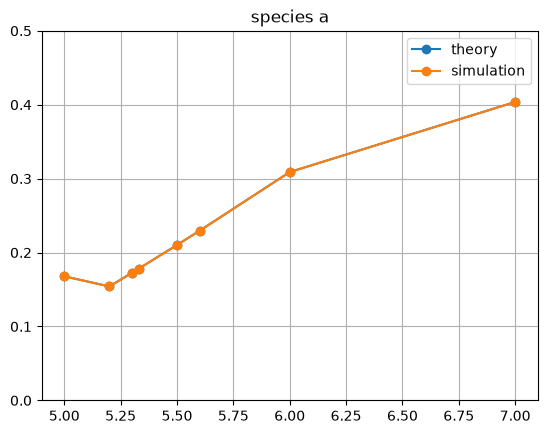

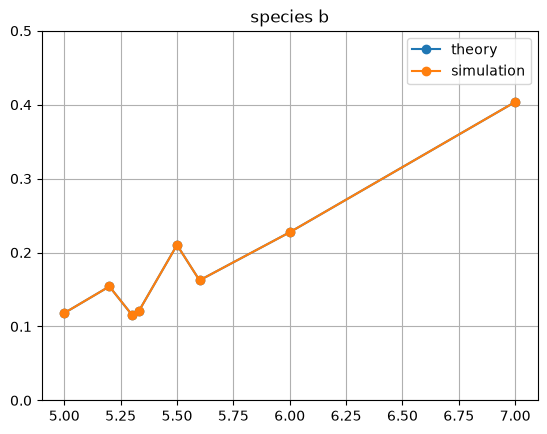

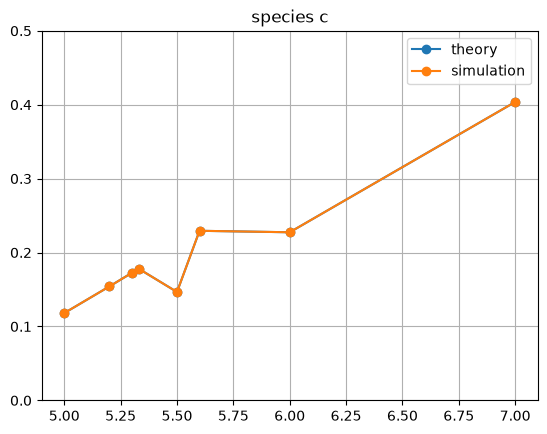

In [70]:
w_theo_all = {"a": [], "b": [], "c": []}
w_exp_all = {"a": [], "b": [], "c": []}
for pa, pb, pc, c in zip(all_a_ps[2:],all_b_ps[2:], all_c_ps[2:], c_vals[2:]):
    print(f"\n---> Handling c={c}\n")
    for ps, species in ((pa, "a"), (pb, "b"), (pc, "c")):
        p = ps[-1]
        print(f"Handling species {species}")
        centers, H, bin_width = hist_of_hist(p, n_bins=150)
        # plt.plot(x, p, "-o")
        # plt.show()
        # plt.plot(centers, H, "-o")
        # plt.show()
        inds = find_peaks(H)[0]
        ell = centers[inds[0]]
        print(f"ell = {ell}")
        w_theo = peak_width_analytical(c, ell)
        peak_ind = np.argmax(p)
        w_sim = peak_widths(p, [peak_ind])[0][0] * 0.02
        print(f"w_theo: {w_theo}")
        print(f"w_exp: {w_sim}")
        print(w_theo)
        w_theo_all[species].append(w_theo) 
        w_exp_all[species].append(w_sim)
for species in ("a", "b", "c"):
    w_theo_vals = w_theo_all[species]
    w_exp_vals = w_theo_all[species]
    plt.plot(c_vals[2:], w_theo_vals, "-o", label="theory")
    plt.plot(c_vals[2:], w_exp_vals, "-o", label="simulation")
    plt.title(f"species {species}")
    plt.grid()
    plt.legend()
    plt.ylim(0, 0.5)
    plt.show()

In [49]:
peak_width_analytical(7, 0.09)

np.float64(0.3193469756013497)

In [192]:
len(all_a_ps[2:])

8

In [193]:
c_vals

[3, 4, 5, 5.2, 5.3, 5.33, 5.5, 5.6, 6, 7]